# 12 · Sampling and discretisation

A digital controller sees the plant through a sampler and acts through a hold: it works with sequences, and
its design works with discrete-time models. This notebook builds the exact zero-order-hold equivalent of a
continuous plant from the matrix exponential, compares it with Tustin's transform (and its prewarped
variant), matched mapping and Euler's rules, shows where the poles go (z = e^{sΔt}) and what the hold costs (a
half-sample delay), demonstrates aliasing, and gives the rules for choosing the sampling rate.

**What you will learn**
- derive the zero-order-hold equivalent and its pole mapping
- compare Tustin (with prewarping), matched and Euler discretisations
- quantify the hold's half-sample delay
- explain aliasing and choose a sampling rate

**Before you start:** notebook 01  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere englincontrol is missing): install it from GitHub
    import englincontrol
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/englincontrol"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from englincontrol import systems as sy, discrete as dc, response as rs, frequency as fr, stability as st, models
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The zero-order-hold equivalent is exact

In [2]:
G = sy.tf([4.0], [1.0, 1.2, 4.0])
dt = 0.1
Gd = dc.c2d(G, dt)
print("continuous:", G, "\nZOH equivalent:", Gd)
print("poles map by z = e^{s dt}:", np.round(np.sort_complex(Gd.poles()), 5), "=", np.round(np.sort_complex(np.exp(G.poles() * dt)), 5))
t, y = rs.step(G, 5.0, 51); td, yd = rs.step(Gd, 5.0)
print(f"the discrete step response equals the continuous one at every sample: max difference {np.max(np.abs(y - yd)):.1e}")
Gss = G.to_ss()
print("d2c recovers A by the matrix logarithm:", np.max(np.abs(dc.d2c(dc.c2d(Gss, dt)).A - Gss.A)) < 1e-12)

continuous: TransferFunction(4 / s^2 + 1.2s + 4) 
ZOH equivalent: TransferFunction(0.01916z + 0.01841 / z^2 - 1.849z + 0.8869, dt = 0.1)
poles map by z = e^{s dt}: [0.92468-0.17859j 0.92468+0.17859j] = [0.92468-0.17859j 0.92468+0.17859j]
the discrete step response equals the continuous one at every sample: max difference 4.4e-15
d2c recovers A by the matrix logarithm: True


With a zero-order hold the input is constant between samples, and then x_{k+1} = e^{AΔt} x_k + (∫₀^{Δt} e^{Aτ}dτ) B u_k
is exact - the same formulas as the time responses of notebook 01. The poles move to z = e^{sΔt}: the left
half-plane maps inside the unit circle, the imaginary axis onto it. The zeros do not map so simply: ZOH
discretisation adds sampling zeros, which can even fall outside the unit circle for fast sampling of
high-relative-degree plants - a discrete non-minimum-phase behaviour with no continuous counterpart.

## Tustin, prewarping, matched poles, Euler

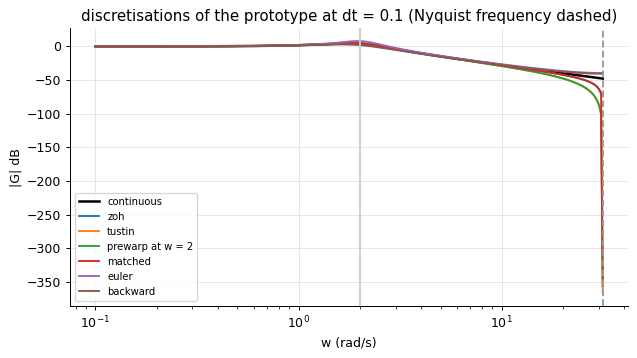

tustin  : |G_d(e^(j 2 dt))| = 1.66100 vs |G(2j)| = 1.66667  (Tustin's warping: the discrete response at w equals the continuous one at (2/dt) tan(w dt/2) = 2.0067)
prewarp : |G_d(e^(j 2 dt))| = 1.66667 vs |G(2j)| = 1.66667
forward Euler of a stable system can be unstable: poles of euler at dt = 1: [1.949 1.949]


In [3]:
w = np.logspace(-1, np.log10(np.pi / dt), 300)
fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogx(w, 20 * np.log10(np.abs(fr.freqresp(G, w))), "k", lw=2, label="continuous")
for meth, kw in (("zoh", {}), ("tustin", {}), ("prewarp", {"w_prewarp": 2.0}), ("matched", {}), ("euler", {}), ("backward", {})):
    Gm = dc.c2d(G, dt, meth, **kw)
    ax.semilogx(w, 20 * np.log10(np.abs(fr.freqresp(Gm, w))), label=meth + (" at w = 2" if kw else ""))
ax.axvline(2.0, color="0.8"); ax.axvline(np.pi / dt, color="0.6", ls="--"); ax.set_xlabel("w (rad/s)"); ax.set_ylabel("|G| dB"); ax.legend(fontsize=8); ax.set_title("discretisations of the prototype at dt = 0.1 (Nyquist frequency dashed)"); plt.show()
for meth, kw in (("tustin", {}), ("prewarp", {"w_prewarp": 2.0})):
    Gm = dc.c2d(G, dt, meth, **kw)
    print(f"{meth:<8}: |G_d(e^(j 2 dt))| = {abs(fr.freqresp(Gm, 2.0)):.5f} vs |G(2j)| = {abs(fr.freqresp(G, 2.0)):.5f}" + ("" if kw else f"  (Tustin's warping: the discrete response at w equals the continuous one at (2/dt) tan(w dt/2) = {2 / dt * np.tan(2.0 * dt / 2):.4f})"))
print("forward Euler of a stable system can be unstable: poles of euler at dt = 1:", np.round(np.abs(dc.c2d(G, 1.0, 'euler').poles()), 3))

Tustin's bilinear transform s = (2/Δt)(z − 1)/(z + 1) maps the whole imaginary axis onto the unit circle, so it
preserves stability and the shape of the frequency response - compressed: the discrete response at ω equals
the continuous one at (2/Δt)tan(ωΔt/2), the warping that prewarping corrects at one chosen frequency (the
resonance, say). Matched mapping places poles and zeros at e^{sΔt} and fixes the dc gain. Forward Euler is
the simplest and the worst: it maps the left half-plane onto a half-plane, not the unit disc, and a stable
system can come out unstable at a large step. For plant models ZOH is the right choice (it *is* what the
hold does); for controllers Tustin is the usual one.

## What the hold costs: a half-sample delay

In [4]:
for dt_ in (0.01, 0.05, 0.1, 0.2):
    H = dc.zoh_frequency_response(2.0, dt_)
    print(f"dt = {dt_:4}: zero-order hold at w = 2: |H| = {abs(H):.5f}, phase {np.degrees(np.angle(H)):+.2f} deg = -w dt/2 = {np.degrees(-2.0 * dt_ / 2):+.2f} deg")
L = sy.tf([10.0], [1.0, 1.0, 0.0])
m0 = fr.margins(L)
print(f"\nthe loop 10/(s(s+1)) has phase margin {m0['phase_margin']:.1f} deg at w_gc = {m0['w_gc']:.2f};")
for dt_ in (0.02, 0.1, 0.3):
    m = fr.margins(L, delay=dt_ / 2)
    print(f"   sampled at dt = {dt_}: the hold's half-sample delay costs {m0['phase_margin'] - m['phase_margin']:.1f} deg of phase margin -> {m['phase_margin']:.1f} deg")

dt = 0.01: zero-order hold at w = 2: |H| = 0.99998, phase -0.57 deg = -w dt/2 = -0.57 deg
dt = 0.05: zero-order hold at w = 2: |H| = 0.99958, phase -2.86 deg = -w dt/2 = -2.86 deg
dt =  0.1: zero-order hold at w = 2: |H| = 0.99833, phase -5.73 deg = -w dt/2 = -5.73 deg
dt =  0.2: zero-order hold at w = 2: |H| = 0.99335, phase -11.46 deg = -w dt/2 = -11.46 deg

the loop 10/(s(s+1)) has phase margin 18.0 deg at w_gc = 3.08;
   sampled at dt = 0.02: the hold's half-sample delay costs 1.8 deg of phase margin -> 16.2 deg
   sampled at dt = 0.1: the hold's half-sample delay costs 8.8 deg of phase margin -> 9.1 deg
   sampled at dt = 0.3: the hold's half-sample delay costs 26.5 deg of phase margin -> -8.5 deg


The zero-order hold's frequency response (1 − e^{−jωΔt})/(jωΔt) has unit magnitude at low frequency and a
phase of −ωΔt/2: it behaves as a delay of half a sample. In a loop with crossover ω_c that delay removes
ω_cΔt/2 radians of phase margin, which is where the sampling-rate rules come from: for the loss to stay
under 5-10°, ω_cΔt must be about 0.2-0.3.

## Aliasing and the sampling rate

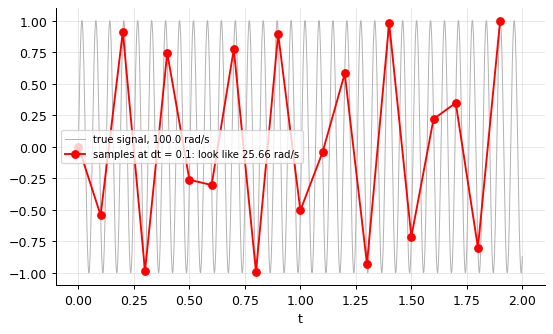

for a closed-loop bandwidth of 5 rad/s: dt between 0.040 and 0.120 s (w_b dt in 0.2-0.6), recommended 0.060 s
an anti-aliasing filter must then attenuate everything above the Nyquist frequency 52 rad/s


In [5]:
fs_dt = 0.1
t_fine = np.linspace(0, 2, 2001)
w_true = 100.0                                                        # above the Nyquist frequency pi/dt = 31.4
x = np.sin(w_true * t_fine)
t_s = np.arange(0, 2, fs_dt)
plt.plot(t_fine, x, "0.7", lw=0.8, label=f"true signal, {w_true} rad/s"); plt.plot(t_s, np.sin(w_true * t_s), "ro-", label=f"samples at dt = {fs_dt}: look like {dc.alias(w_true, fs_dt):.2f} rad/s"); plt.legend(fontsize=8); plt.xlabel("t"); plt.show()
rules = dc.sample_rate_rules(5.0)
print(f"for a closed-loop bandwidth of 5 rad/s: dt between {rules['dt_min']:.3f} and {rules['dt_max']:.3f} s (w_b dt in 0.2-0.6), recommended {rules['dt_recommended']:.3f} s")
print(f"an anti-aliasing filter must then attenuate everything above the Nyquist frequency {dc.nyquist_frequency(rules['dt_recommended']):.0f} rad/s")

A 100 rad/s component sampled at Δt = 0.1 is indistinguishable from one at 25.7 rad/s: it folds back into the
band the controller acts on and appears as a slow disturbance that is not there. Hence the two rules of digital
control: sample fast enough for the loop (ω_bΔt ≈ 0.2-0.6, a compromise between the hold's delay and the
numerical problems of very fast sampling seen in notebook 15), and filter the measurement before sampling so
that nothing above the Nyquist frequency reaches the sampler.

## Inside the algorithm: Tustin's transform on the state-space matrices

In [6]:
Ac, Bc, Cc, Dc = Gss.A, Gss.B, Gss.C, Gss.D
k = 2 / dt
M = np.linalg.inv(k * np.eye(2) - Ac)
Ad_hand = M @ (k * np.eye(2) + Ac)
print("Tustin A by hand:\n", np.round(Ad_hand, 6), "\nlibrary:\n", np.round(dc.c2d(Gss, dt, 'tustin').A, 6))

Tustin A by hand:
 [[ 0.869159 -0.373832]
 [ 0.093458  0.981308]] 
library:
 [[ 0.869159 -0.373832]
 [ 0.093458  0.981308]]


## Exercises
1. Discretise the prototype G at dt = 0.1, 0.5, 1.0 and 1.5 by ZOH and by Tustin and compare the step responses with the continuous one at the samples. Which method is exact at the samples whatever dt, and which preserves stability whatever dt?
2. The ZOH discretisation of 1/s^3 at small dt has zeros outside the unit circle (sampling zeros). Find them with `dc.c2d(sy.tf([1.0], [1, 0, 0, 0]), dt).zeros()` for dt = 0.1 and explain why a dead-beat or inverse-based digital controller would fail here.
3. **Implement it yourself:** compute the ZOH matrices (Phi, Gamma) by the series expansion Phi = sum (A dt)^k/k!, Gamma = sum A^k dt^(k+1)/(k+1)! B truncated at 20 terms and compare with `linalg.expm_with_integral` for the DC motor at dt = 0.01 and at dt = 1.